# Zhang et al. 2021 — RCC (Kidney) · 04 EMT-TF Expression

Unconditional final step (renumbered 04: Gate 2 GO non-branching, Gate 3 NA -> no branching-only
correlation/modules notebooks). EMT transcription factors scored on this dataset, gated on
detectable expression, spanning mesenchymal families (Snail/Zeb/Twist + FOXC/PRRX). Categorical
overlay of thresholded expressers on a grey manifold (house style), not a continuous colormap.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 11218 | pseudotime range 0.0 -> 8.89


## Detection-gated EMT-TF panel

In [5]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
# Single ordering signal used consistently for the table lean AND the displayed pair:
# pt_expr = mean pseudotime of a TF's expressing cells (lower = root-leaning onset).
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho,p = spearmanr(tn, x)
    pt_expr = float(tn[expr].mean()) if expr.any() else np.nan
    rows.append((g, round(expr.mean(),3), round(pt_expr,3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','pt_expr','rho_vs_t'])
# lean by the SAME signal that orders the pair: expressers' mean pseudotime vs the global mean (tn ~ 0.5)
df['lean'] = np.where(df.pt_expr < tn.mean(), 'root-leaning', 'terminus-leaning')
df = df.sort_values('frac_expr', ascending=False)
print(f'global mean pseudotime (tn) = {tn.mean():.3f} (lean split point)')
print(df.to_string(index=False))
# two best-detected TFs from DIFFERENT families (Zeb vs Foxc dominate here)
ok = df[df.frac_expr > 0.03].copy()
fam = {'SNAI1':'Snail','SNAI2':'Snail','ZEB1':'Zeb','ZEB2':'Zeb','TWIST1':'Twist','TWIST2':'Twist',
       'FOXC1':'Foxc','FOXC2':'Foxc','PRRX1':'Prrx','PRRX2':'Prrx'}
ok['family'] = ok['TF'].map(fam)
picks, seen = [], set()
for _,rr in ok.sort_values('frac_expr', ascending=False).iterrows():
    if rr['family'] not in seen: picks.append(rr['TF']); seen.add(rr['family'])
    if len(picks)==2: break
tf_a, tf_b = picks
# order the displayed pair by pt_expr (the SAME signal as the table 'lean' column)
pt = {g: float(df.set_index('TF').loc[g,'pt_expr']) for g in [tf_a, tf_b]}
if pt[tf_a] > pt[tf_b]: tf_a, tf_b = tf_b, tf_a
print(f'\nderived EMT-TF pair (best-detected, distinct families): '
      f'{tf_a} (pt_expr {pt[tf_a]:.2f}, earlier onset) . {tf_b} (pt_expr {pt[tf_b]:.2f}, later onset)')
print('(both root-leaning: on a non-branching manifold no TF is strongly terminus-specific)')

global mean pseudotime (tn) = 0.476 (lean split point)
    TF  frac_expr  pt_expr  rho_vs_t             lean
  ZEB2      0.238    0.421    -0.088     root-leaning
 FOXC2      0.122    0.456    -0.017     root-leaning
 FOXC1      0.083    0.392    -0.070     root-leaning
  ZEB1      0.059    0.445    -0.020     root-leaning
 SNAI2      0.032    0.461    -0.009     root-leaning
 SNAI1      0.030    0.420    -0.033     root-leaning
 PRRX1      0.003    0.397    -0.011     root-leaning
TWIST1      0.001    0.196    -0.018     root-leaning
TWIST2      0.001    0.648     0.011 terminus-leaning
 PRRX2      0.001    0.676     0.016 terminus-leaning

derived EMT-TF pair (best-detected, distinct families): ZEB2 (pt_expr 0.42, earlier onset) . FOXC2 (pt_expr 0.46, later onset)
(both root-leaning: on a non-branching manifold no TF is strongly terminus-specific)


## EMT-TF categorical overlay (thresholded expressers on grey)

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.8, 'FOXC2': 0.807} | cells shown: {'ZEB2': 667, 'FOXC2': 343}
ZEB2: 23.8% expressing; 667 shown, mean pt of shown = 0.37 (all = 0.48)
FOXC2: 12.2% expressing; 343 shown, mean pt of shown = 0.42 (all = 0.48)
saved expression.pdf


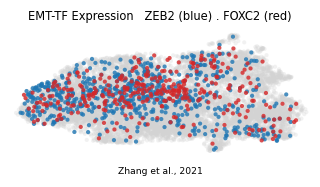

In [7]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_a, tf_b]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_a, tf_b]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf_a,tf_b]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [tf_a,tf_b]})
order = sorted([tf_a, tf_b], key=lambda g: -int(sel[g].sum()))
colors = {tf_a:'tab:blue', tf_b:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {tf_a} (blue) . {tf_b} (red)', size=7.5)
ax.text(.5,-.14,'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [tf_a, tf_b]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, mean pt of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')